# Association Rule Mining — Dataset Apotek

### 4.1 Persiapan Data Transaksi

In [1]:
%pip install -q mlxtend

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

def assoc(fi, metric='confidence', min_threshold=0.6):
    # kompatibel untuk berbagai versi mlxtend
    try:
        return association_rules(fi, metric=metric, min_threshold=min_threshold)
    except TypeError:
        return association_rules(fi, num_itemsets=len(df), metric=metric, min_threshold=min_threshold)

# Membaca dataset transaksi mentah
data = pd.read_csv('apotek_transactions.csv', encoding='utf-8-sig')

# transactions: list berisi transaksi (daftar item per transaksi)
transactions = [items.split(', ') for items in data['Items']]

print('Jumlah transaksi:', len(transactions))
for i, t in enumerate(transactions[:5], 1):
    print(f'T{i}: {t}')

Jumlah transaksi: 60
T1: ['Vitamin C', 'Suplemen Vitamin B', 'Masker Medis', 'Termometer']
T2: ['Masker Medis', 'Hand Sanitizer', 'Tisu Antiseptik']
T3: ['Plester Luka', 'Betadine', 'Alkohol Swab']
T4: ['Paracetamol', 'Termometer']
T5: ['Paracetamol', 'Minyak Kayu Putih', 'Vitamin C']


In [3]:
from collections import Counter
cnt = Counter()
for t in transactions:
    cnt.update(t)
for item, freq in cnt.most_common():
    print(f'{item:20s}: {freq:2d} (support = {freq/len(transactions):.3f})')

Masker Medis        : 23 (support = 0.383)
Vitamin C           : 17 (support = 0.283)
Hand Sanitizer      : 17 (support = 0.283)
Plester Luka        : 15 (support = 0.250)
Suplemen Vitamin B  : 12 (support = 0.200)
Tisu Antiseptik     : 12 (support = 0.200)
Betadine            : 12 (support = 0.200)
Alkohol Swab        : 12 (support = 0.200)
Termometer          : 11 (support = 0.183)
Paracetamol         : 11 (support = 0.183)
Oralit              :  8 (support = 0.133)
Minyak Kayu Putih   :  6 (support = 0.100)


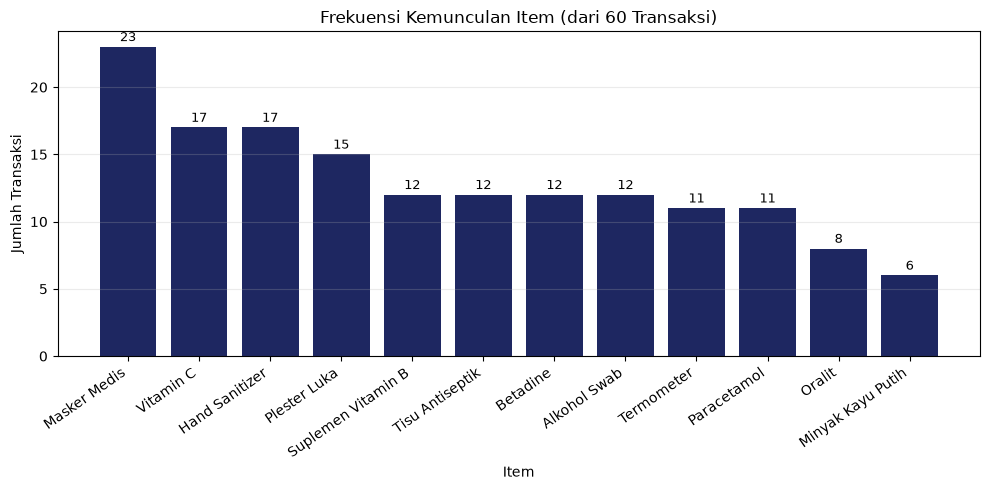

In [4]:
import matplotlib.pyplot as plt

items = [item for item, freq in cnt.most_common()]
frequencies = [freq for item, freq in cnt.most_common()]

plt.figure(figsize=(10, 5))
bars = plt.bar(items, frequencies, color='#1E2761')

plt.title(f'Frekuensi Kemunculan Item (dari {len(transactions)} Transaksi)')
plt.xlabel('Item')
plt.ylabel('Jumlah Transaksi')
plt.xticks(rotation=35, ha='right')
plt.grid(axis='y', alpha=0.25)

# Menampilkan angka frekuensi di atas setiap batang
for bar, freq in zip(bars, frequencies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        str(freq),
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()

### 4.2 Encoding Data Transaksi ke Format One-Hot

In [5]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)

print('Ukuran matriks one-hot:', df.shape)
print(df.iloc[:5, :6])

Ukuran matriks one-hot: (60, 12)
   Alkohol Swab  Betadine  Hand Sanitizer  Masker Medis  Minyak Kayu Putih  \
0         False     False           False          True              False   
1         False     False            True          True              False   
2          True      True           False         False              False   
3         False     False           False         False              False   
4         False     False           False         False               True   

   Oralit  
0   False  
1   False  
2   False  
3   False  
4   False  


In [6]:
# Membaca dataset one-hot yang dilampirkan untuk memeriksa kesesuaian hasil encoding
df_onehot = pd.read_csv('apotek_transactions_onehot.csv', encoding='utf-8-sig')

# Menyamakan urutan kolom sebelum dibandingkan
df_onehot = df_onehot.reindex(columns=df.columns)

print('Ukuran dataset one-hot terlampir:', df_onehot.shape)
print('Apakah hasil encoding sama dengan dataset one-hot terlampir?',
      df.equals(df_onehot.astype(bool)))

Ukuran dataset one-hot terlampir: (60, 12)
Apakah hasil encoding sama dengan dataset one-hot terlampir? True


### 4.3 Mencari Frequent Itemset dengan Algoritma Apriori

In [7]:
MIN_SUP = 0.10
freq_apriori = apriori(df, min_support=MIN_SUP, use_colnames=True)
freq_apriori = freq_apriori.sort_values('support', ascending=False)
print('Jumlah frequent itemset:', len(freq_apriori))
print(freq_apriori.to_string(index=False))

Jumlah frequent itemset: 28
 support                                        itemsets
0.383333                                  (Masker Medis)
0.283333                                (Hand Sanitizer)
0.283333                                     (Vitamin C)
0.250000                                  (Plester Luka)
0.216667                  (Masker Medis, Hand Sanitizer)
0.200000                                  (Alkohol Swab)
0.200000                            (Suplemen Vitamin B)
0.200000                                      (Betadine)
0.200000                        (Plester Luka, Betadine)
0.200000                       (Vitamin C, Masker Medis)
0.200000                               (Tisu Antiseptik)
0.183333                                   (Paracetamol)
0.183333                                    (Termometer)
0.166667                 (Suplemen Vitamin B, Vitamin C)
0.133333                                        (Oralit)
0.116667              (Suplemen Vitamin B, Masker Medis)
0.1

### 4.4 Membentuk Aturan Asosiasi

In [8]:
MIN_CONF = 0.60
rules = assoc(freq_apriori, metric='confidence', min_threshold=MIN_CONF)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

print('Jumlah aturan asosiasi:', len(rules))

cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
display(rules[cols].round(3))

Jumlah aturan asosiasi: 12


,antecedents,consequents,support,confidence,lift
0,"(Plester Luka, Alkohol Swab)",(Betadine),0.100,1.000,5.000
1,(Oralit),(Termometer),0.100,0.750,4.091
2,(Betadine),(Plester Luka),0.200,1.000,4.000
3,(Plester Luka),(Betadine),0.200,0.800,4.000
4,"(Betadine, Alkohol Swab)",(Plester Luka),0.100,1.000,4.000
5,"(Suplemen Vitamin B, Masker Medis)",(Vitamin C),0.117,1.000,3.529
6,"(Tisu Antiseptik, Masker Medis)",(Hand Sanitizer),0.100,1.000,3.529
7,(Suplemen Vitamin B),(Vitamin C),0.167,0.833,2.941
8,"(Tisu Antiseptik, Hand Sanitizer)",(Masker Medis),0.100,1.000,2.609
9,(Hand Sanitizer),(Masker Medis),0.217,0.765,1.995


### 4.5 Visualisasi Hasil

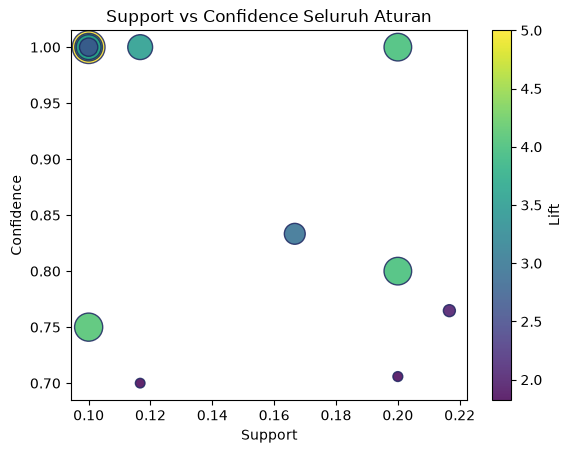

In [9]:
import matplotlib.pyplot as plt

sizes = (rules['lift'] - rules['lift'].min() + 0.3) * 160
sc = plt.scatter(rules['support'], rules['confidence'], s=sizes,
                 c=rules['lift'], cmap='viridis', alpha=0.85, edgecolor='#1E2761')
plt.colorbar(sc, label='Lift')
plt.xlabel('Support'); plt.ylabel('Confidence')
plt.title('Support vs Confidence Seluruh Aturan')
plt.show()

### 4.6 Interpretasi Bisnis dari Aturan Terpilih

In [10]:
cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
print(rules[cols].head(10).round(3).to_string(index=False))

                       antecedents      consequents  support  confidence  lift
      (Plester Luka, Alkohol Swab)       (Betadine)    0.100       1.000 5.000
                          (Oralit)     (Termometer)    0.100       0.750 4.091
                        (Betadine)   (Plester Luka)    0.200       1.000 4.000
                    (Plester Luka)       (Betadine)    0.200       0.800 4.000
          (Betadine, Alkohol Swab)   (Plester Luka)    0.100       1.000 4.000
(Suplemen Vitamin B, Masker Medis)      (Vitamin C)    0.117       1.000 3.529
   (Tisu Antiseptik, Masker Medis) (Hand Sanitizer)    0.100       1.000 3.529
              (Suplemen Vitamin B)      (Vitamin C)    0.167       0.833 2.941
 (Tisu Antiseptik, Hand Sanitizer)   (Masker Medis)    0.100       1.000 2.609
                  (Hand Sanitizer)   (Masker Medis)    0.217       0.765 1.995


### 4.7 Eksperimen: Pengaruh Nilai `min_support`

In [11]:
sweep_sup = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
for s in sweep_sup:
    fi = apriori(df, min_support=s, use_colnames=True)
    r = assoc(fi, metric='confidence', min_threshold=MIN_CONF) if len(fi) else pd.DataFrame()
    print(f'min_support={s:.2f}: {len(fi):2d} itemset, {len(r):2d} aturan')

min_support=0.10: 28 itemset, 12 aturan
min_support=0.15: 14 itemset,  5 aturan
min_support=0.20: 11 itemset,  4 aturan
min_support=0.25:  4 itemset,  0 aturan
min_support=0.30:  1 itemset,  0 aturan
min_support=0.35:  1 itemset,  0 aturan
min_support=0.40:  0 itemset,  0 aturan


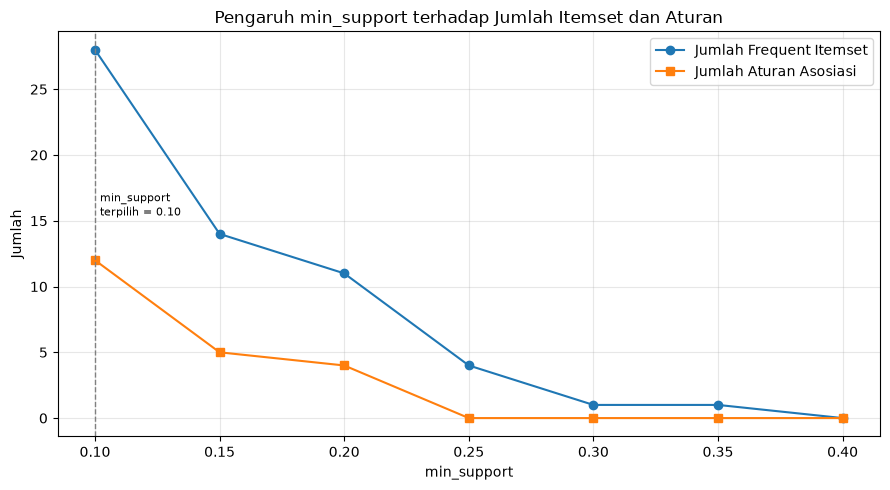

In [12]:
# Grafik Pengaruh Nilai min_support
jumlah_itemset = []
jumlah_aturan = []

for s in sweep_sup:
    fi = apriori(df, min_support=s, use_colnames=True)
    r = assoc(fi, metric='confidence', min_threshold=MIN_CONF) if len(fi) else pd.DataFrame()

    jumlah_itemset.append(len(fi))
    jumlah_aturan.append(len(r))

plt.figure(figsize=(9, 5))

plt.plot(sweep_sup, jumlah_itemset, marker='o',
         label='Jumlah Frequent Itemset')

plt.plot(sweep_sup, jumlah_aturan, marker='s',
         label='Jumlah Aturan Asosiasi')

plt.axvline(x=0.10, color='gray', linestyle='--', linewidth=1)

plt.text(0.102, max(jumlah_itemset + jumlah_aturan) * 0.55,
         'min_support\nterpilih = 0.10', fontsize=8)

plt.xlabel('min_support')
plt.ylabel('Jumlah')
plt.title('Pengaruh min_support terhadap Jumlah Itemset dan Aturan')
plt.xticks(sweep_sup)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 4.8 Eksperimen: Apriori vs FP-Growth

In [13]:
import time

t0 = time.perf_counter()
freq_apriori = apriori(df, min_support=0.10, use_colnames=True)
t_apriori = time.perf_counter() - t0

t0 = time.perf_counter()
freq_fpgrowth = fpgrowth(df, min_support=0.10, use_colnames=True)
t_fpgrowth = time.perf_counter() - t0

set_apriori = set(frozenset(s) for s in freq_apriori['itemsets'])
set_fpgrowth = set(frozenset(s) for s in freq_fpgrowth['itemsets'])
print(f'Apriori : {len(freq_apriori)} itemset, {t_apriori*1000:.2f} ms')
print(f'FP-Growth: {len(freq_fpgrowth)} itemset, {t_fpgrowth*1000:.2f} ms')
print('Itemset identik?', set_apriori == set_fpgrowth)

Apriori : 28 itemset, 3.96 ms
FP-Growth: 28 itemset, 2.83 ms
Itemset identik? True


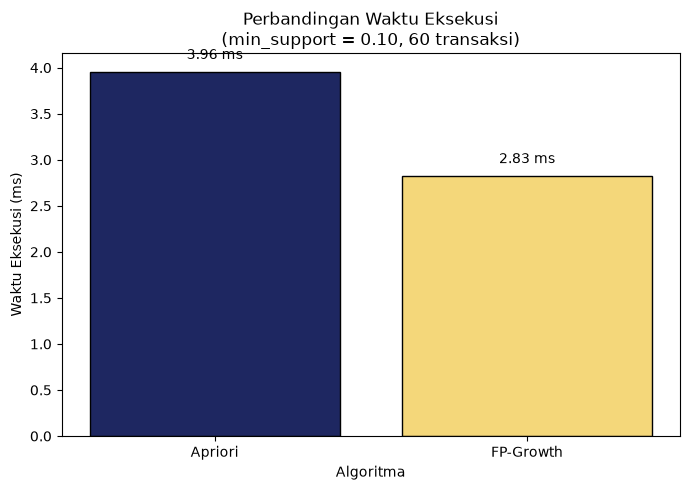

In [14]:
# Grafik Perbandingan Waktu Eksekusi Apriori vs FP-Growth
algoritma = ['Apriori', 'FP-Growth']
waktu = [t_apriori * 1000, t_fpgrowth * 1000]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    algoritma,
    waktu,
    color=['#1E2761', '#F4D77A'],
    edgecolor='black'
)

plt.ylabel('Waktu Eksekusi (ms)')
plt.xlabel('Algoritma')
plt.title(f'Perbandingan Waktu Eksekusi\n(min_support = 0.10, {len(transactions)} transaksi)')

# Menampilkan nilai waktu di atas batang
for bar, value in zip(bars, waktu):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f'{value:.2f} ms',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()